[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wilsonsr/analisis-multivariado-lasalle/blob/main/notebooks/02a_correspondencias_simple_y_multiple.ipynb)

# Unidad 2 · Análisis de correspondencias simple y múltiple

**Análisis Multivariado** · Programa de Ciencia de Datos · Universidad de La Salle
**Unidad 2: Asociaciones y estructuras latentes en datos multivariados** · Complemento de la *Guía de la Unidad 2*
Autor: Wilson Sandoval Rodríguez (2026)

En este cuaderno vas a:
- Construir una tabla de contingencia y verificar la asociación con la prueba chi-cuadrado.
- Calcular perfiles, masas, distancias chi-cuadrado e inercia.
- Obtener el ACS paso a paso con la descomposición en valores singulares e interpretar el mapa.
- Construir la tabla disyuntiva completa y aplicar el ACM con prince.
- Corregir los porcentajes de inercia del ACM y valorar el efecto de categorías poco frecuentes.

> Los datos son **simulados con fines didácticos**. Las cifras que aparecen en la guía se obtuvieron ejecutando este mismo código con las versiones indicadas en `requirements.txt`. Con otras versiones pueden cambiar el signo de un componente o los últimos decimales.

## 0. Configuración

In [1]:
# Configuración: en Colab instala lo necesario; en local usa los datos del repositorio
import sys, os
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    get_ipython().system("pip install -q prince==0.23.1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import prince
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

RUTA_LOCAL = os.path.join("..", "data", "datos_guia2_encuesta_salud.csv")
RUTA_WEB = "https://raw.githubusercontent.com/wilsonsr/analisis-multivariado-lasalle/main/data/datos_guia2_encuesta_salud.csv"
ruta = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else RUTA_WEB

In [2]:
encuesta = pd.read_csv(ruta)
print(encuesta.shape)
encuesta.head()

(600, 15)


,id,zona,nivel_educativo,regimen,consulta_preventiva,percepcion_calidad,inst_limpieza,inst_comodidad,inst_equipos,trato_amabilidad,trato_escucha,trato_explicacion,opor_cita,opor_espera,opor_tramites
0,1,Urbana,Secundaria,Subsidiado,No,Mala,2,2,3,4,3,2,4,2,4
1,2,Urbana,Universitaria,Contributivo,No,Regular,3,2,3,2,1,1,3,4,3
2,3,Urbana,Universitaria,Contributivo,Sí,Buena,5,4,5,4,5,3,3,4,5
3,4,Urbana,Técnica,Contributivo,Sí,Buena,4,4,4,5,5,5,4,4,3
4,5,Urbana,Universitaria,Contributivo,Sí,Regular,3,3,4,4,2,4,2,1,1


## Parte A · Análisis de correspondencias simple (ACS)

**Pregunta:** ¿se asocia el nivel educativo con el régimen de afiliación al sistema de salud?

### A.1 Tabla de contingencia y prueba chi-cuadrado

In [3]:
orden = ["Primaria", "Secundaria", "Técnica", "Universitaria"]
N = pd.crosstab(encuesta["nivel_educativo"], encuesta["regimen"]).loc[orden]
chi2, p, gl, esperadas = chi2_contingency(N)
print(N, "\n")
print(f"Chi-cuadrado = {chi2:.2f}, gl = {gl}, p = {p:.2e}")
print("Celdas con frecuencia esperada < 5:", int((esperadas < 5).sum()), "de", esperadas.size)
pd.DataFrame(esperadas, index=N.index, columns=N.columns).round(1)

regimen          Contributivo  Especial  No afiliado  Subsidiado
nivel_educativo                                                 
Primaria                   28         6           24         116
Secundaria                 69         2           16          86
Técnica                    69         3            6          36
Universitaria             108        14            5          12 

Chi-cuadrado = 166.75, gl = 9, p = 2.93e-31
Celdas con frecuencia esperada < 5: 1 de 16


regimen,Contributivo,Especial,No afiliado,Subsidiado
nivel_educativo,,,,
Primaria,79.5,7.2,14.8,72.5
Secundaria,79.0,7.2,14.7,72.1
Técnica,52.1,4.8,9.7,47.5
Universitaria,63.5,5.8,11.8,57.9


**¿Qué observar?** χ² = 166,75 con 9 gl y p < 0,001: hay asociación. Una sola celda (Técnica–Especial, 4,75) tiene frecuencia esperada menor que 5; está por debajo del umbral del 20 % de celdas, pero advierte que «Especial» es poco frecuente (25 personas).

### A.2 Masas, perfiles y distancia chi-cuadrado

In [4]:
n = N.values.sum()
P = N / n
r = P.sum(axis=1)                 # masas de las filas
cm = P.sum(axis=0)                # masas de las columnas = perfil medio
perfiles = N.div(N.sum(axis=1), axis=0)
print("Masas fila:\n", r.round(3), "\n\nPerfil medio:\n", cm.round(3))
perfiles.round(3)

Masas fila:
 nivel_educativo
Primaria         0.290
Secundaria       0.288
Técnica          0.190
Universitaria    0.232
dtype: float64 

Perfil medio:
 regimen
Contributivo    0.457
Especial        0.042
No afiliado     0.085
Subsidiado      0.417
dtype: float64


regimen,Contributivo,Especial,No afiliado,Subsidiado
nivel_educativo,,,,
Primaria,0.161,0.034,0.138,0.667
Secundaria,0.399,0.012,0.092,0.497
Técnica,0.605,0.026,0.053,0.316
Universitaria,0.777,0.101,0.036,0.086


In [5]:
def dist_chi2(a, b):
    """Distancia chi-cuadrado entre dos perfiles fila (raíz de la suma ponderada)."""
    return np.sqrt((((perfiles.loc[a] - perfiles.loc[b])**2) / cm).sum())

for a, b in [("Primaria", "Secundaria"), ("Primaria", "Universitaria")]:
    d = dist_chi2(a, b)
    print(f"{a}–{b}: d = {d:.2f}   d² = {d**2:.2f}")

Primaria–Secundaria: d = 0.48   d² = 0.23
Primaria–Universitaria: d = 1.37   d² = 1.87


### A.3 Descomposición de la inercia (SVD de los residuos estandarizados)

In [6]:
S = (P.values - np.outer(r, cm)) / np.sqrt(np.outer(r, cm))
U, dsv, Vt = np.linalg.svd(S, full_matrices=False)
inercia = dsv**2
print("Inercia total:", inercia.sum().round(4), " = chi2/n:", round(chi2 / n, 4))
pd.DataFrame({"inercia": inercia, "%": 100 * inercia / inercia.sum(),
              "acum_%": 100 * np.cumsum(inercia) / inercia.sum()}).round(3).head(3)

Inercia total: 0.2779  = chi2/n: 0.2779


,inercia,%,acum_%
0,0.263,94.535,94.535
1,0.015,5.455,99.990
2,0.000,0.010,100.000


In [7]:
# Coordenadas principales; orientamos la dimensión 1 para que Primaria sea positiva (como FactoMineR)
F = U[:, :2] * dsv[:2] / np.sqrt(r.values)[:, None]
G = Vt.T[:, :2] * dsv[:2] / np.sqrt(cm.values)[:, None]
for k in range(2):
    if F[0, k] < 0:
        F[:, k] *= -1; G[:, k] *= -1
filas = pd.DataFrame(F, index=N.index, columns=["Dim1", "Dim2"])
cols = pd.DataFrame(G, index=N.columns, columns=["Dim1", "Dim2"])
filas["ctr1_%"] = 100 * r.values * F[:, 0]**2 / inercia[0]
filas["ctr2_%"] = 100 * r.values * F[:, 1]**2 / inercia[1]
d2_centro = (((perfiles - cm)**2) / cm).sum(axis=1).values   # distancia² de cada perfil al perfil medio
filas["cos2_1"] = F[:, 0]**2 / d2_centro
cols["ctr1_%"] = 100 * cm.values * G[:, 0]**2 / inercia[0]
cols["ctr2_%"] = 100 * cm.values * G[:, 1]**2 / inercia[1]
print(filas.round(3)); print(cols.round(3))

                  Dim1   Dim2  ctr1_%  ctr2_%  cos2_1
nivel_educativo                                      
Primaria         0.602  0.114  40.039  24.843   0.965
Secundaria       0.180 -0.113   3.560  24.323   0.717
Técnica         -0.261 -0.150   4.924  28.320   0.750
Universitaria   -0.764  0.121  51.477  22.513   0.975
               Dim1   Dim2  ctr1_%  ctr2_%
regimen                                   
Contributivo -0.507 -0.056  44.715   9.310
Especial     -0.586  0.554   5.441  84.418
No afiliado   0.457  0.100   6.761   5.655
Subsidiado    0.521 -0.015  43.083   0.617


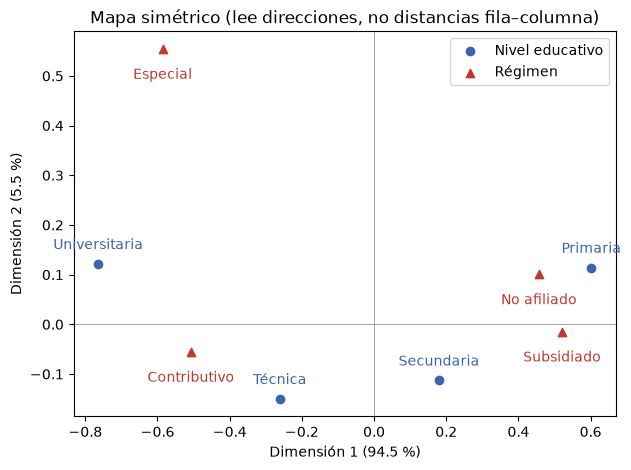

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(filas["Dim1"], filas["Dim2"], color="#3B64B4", label="Nivel educativo")
ax.scatter(cols["Dim1"], cols["Dim2"], color="#C0392B", marker="^", label="Régimen")
for t, (x, y) in filas[["Dim1", "Dim2"]].iterrows():
    ax.text(x, y + 0.03, t, color="#3B64B4", ha="center")
for t, (x, y) in cols[["Dim1", "Dim2"]].iterrows():
    ax.text(x, y - 0.06, t, color="#C0392B", ha="center")
ax.axhline(0, lw=0.5, color="gray"); ax.axvline(0, lw=0.5, color="gray")
pct = 100 * inercia / inercia.sum()
ax.set_xlabel(f"Dimensión 1 ({pct[0]:.1f} %)"); ax.set_ylabel(f"Dimensión 2 ({pct[1]:.1f} %)")
ax.legend(); ax.set_title("Mapa simétrico (lee direcciones, no distancias fila–columna)")
plt.show()

**¿Qué observar?** La dimensión 1 recoge el 94,5 % de la inercia y opone Primaria, Subsidiado y No afiliado a Universitaria y Contributivo: un gradiente educativo de la afiliación. La dimensión 2 (5,5 %) la construye casi solo «Especial» (84,4 % de contribución entre las columnas), una categoría poco frecuente: interprétala con prudencia.

### ✍️ Tu turno

Aplica un ACS a la tabla **zona × percepción de calidad**. ¿Hay asociación? ¿Cuántas dimensiones tiene el mapa y qué categorías se asocian?

*Pista:* con dos filas, el número máximo de dimensiones es min(2 − 1, 3 − 1).

<details>
<summary><b>Ver una solución posible</b></summary>

```python
Nz = pd.crosstab(encuesta["zona"], encuesta["percepcion_calidad"])[["Buena", "Regular", "Mala"]]
chi2_contingency(Nz)
Nz.div(Nz.sum(axis=1), axis=0)
```

La tabla tiene χ² = 94,01 con 2 grados de libertad (p = 3.9e-21). La inercia total es 0,1567 y, con una tabla 2 × 3, hay una sola dimensión. El 45,5 % de las personas rurales percibe mala calidad, frente al 17,5 % de las urbanas: la zona rural se asocia con la percepción «Mala» y la urbana con «Buena».

</details>

## Parte B · Análisis de correspondencias múltiples (ACM)

**Pregunta:** ¿qué perfiles de características sociodemográficas y de acceso tienden a presentarse juntos?

### B.1 Tabla disyuntiva completa y frecuencias

In [9]:
vars_acm = ["zona", "nivel_educativo", "regimen", "consulta_preventiva", "percepcion_calidad"]
Xc = encuesta[vars_acm].astype("category")
Zd = pd.get_dummies(Xc)                 # tabla disyuntiva completa
print(Zd.shape)                         # 600 individuos x 15 categorías
Zd.sum().sort_values()                  # revisa categorías poco frecuentes

(600, 15)


regimen_Especial                  25
regimen_No afiliado               51
nivel_educativo_Técnica          114
nivel_educativo_Universitaria    139
percepcion_calidad_Mala          167
nivel_educativo_Secundaria       173
nivel_educativo_Primaria         174
percepcion_calidad_Regular       213
percepcion_calidad_Buena         220
zona_Rural                       222
regimen_Subsidiado               250
regimen_Contributivo             274
consulta_preventiva_Sí           281
consulta_preventiva_No           319
zona_Urbana                      378
dtype: int64

### B.2 ACM, inercia y corrección de Greenacre

In [10]:
Q, J = len(vars_acm), Zd.shape[1]
acm = prince.MCA(n_components=J - Q, random_state=2026).fit(Xc)
lam = np.array(acm.eigenvalues_)
print("Inercia total J/Q - 1 =", J / Q - 1, "| promedio 1/Q =", 1 / Q)
# Corrección de Greenacre (2008): solo dimensiones con valor propio > 1/Q
ajust = np.where(lam > 1 / Q, (Q / (Q - 1))**2 * (lam - 1 / Q)**2, 0)
total_aj = Q / (Q - 1) * ((lam**2).sum() - (J - Q) / Q**2)
pd.DataFrame({"valor_propio": lam, "%_bruto": 100 * lam / lam.sum(),
              "%_Greenacre": 100 * ajust / total_aj}).round(3).head(5)

Inercia total J/Q - 1 = 2.0 | promedio 1/Q = 0.2


,valor_propio,%_bruto,%_Greenacre
0,0.451,22.558,88.700
1,0.233,11.666,1.561
2,0.211,10.543,0.166
3,0.205,10.262,0.039
4,0.198,9.879,0.000


**¿Qué observar?** El porcentaje bruto de la dimensión 1 (22,6 %) es pesimista por construcción; con la corrección de Greenacre sube a 88,7 %, y la dimensión 2 queda en 1,6 %. Las dimensiones 3 y 4 superan apenas el promedio 0,20: son ruido.

### B.3 Coordenadas de las categorías y relación de cada variable con las dimensiones (η²)

In [11]:
coord = acm.column_coordinates(Xc).iloc[:, :2]
coord.columns = ["Dim1", "Dim2"]
filas_ind = acm.row_coordinates(Xc).iloc[:, :2].values

def eta2(variable, k):
    """Razón de correlación: varianza entre categorías / varianza total de las coordenadas."""
    y = filas_ind[:, k]
    g = encuesta[variable]
    medias = pd.Series(y).groupby(g.values).transform("mean")
    return ((medias - y.mean())**2).sum() / ((y - y.mean())**2).sum()

print(pd.DataFrame({v: [eta2(v, 0), eta2(v, 1)] for v in vars_acm}, index=["Dim1", "Dim2"]).T.round(3))
coord.round(3)

                      Dim1   Dim2
zona                 0.406  0.076
nivel_educativo      0.639  0.523
regimen              0.372  0.563
consulta_preventiva  0.344  0.000
percepcion_calidad   0.495  0.005


,Dim1,Dim2
zona__Rural,0.831,0.359
zona__Urbana,-0.488,-0.211
nivel_educativo__Primaria,1.039,0.436
nivel_educativo__Secundaria,0.155,-0.793
nivel_educativo__Técnica,-0.503,-0.627
nivel_educativo__Universitaria,-1.081,0.955
regimen__Contributivo,-0.624,-0.023
regimen__Especial,-0.429,3.466
regimen__No afiliado,0.790,0.245
regimen__Subsidiado,0.566,-0.371


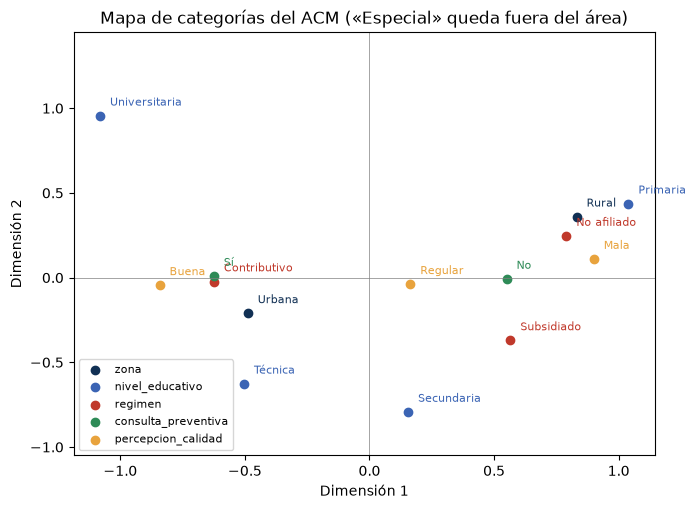

In [12]:
colores = {"zona": "#113054", "nivel_educativo": "#3B64B4", "regimen": "#C0392B",
           "consulta_preventiva": "#2E8B57", "percepcion_calidad": "#E8A33D"}
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for v, col in colores.items():
    sub = coord[coord.index.str.startswith(v + "__")]
    ax.scatter(sub["Dim1"], sub["Dim2"], color=col, label=v)
    for t, (x, y) in sub.iterrows():
        if y < 3:
            ax.text(x + 0.04, y + 0.06, t.split("__")[1], fontsize=8, color=col)
ax.set_ylim(-1.05, 1.45); ax.axhline(0, lw=0.5, color="gray"); ax.axvline(0, lw=0.5, color="gray")
ax.set_xlabel("Dimensión 1"); ax.set_ylabel("Dimensión 2"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Mapa de categorías del ACM («Especial» queda fuera del área)")
plt.show()

**¿Qué observar?** A la derecha de la dimensión 1 se agrupan Rural, Primaria, No afiliado, Subsidiado, «No» consulta y percepción mala; a la izquierda, el perfil opuesto. Es un gradiente de condiciones de acceso. La categoría «Especial» (coordenada 3,47 en la dimensión 2) domina ese eje.

### B.4 Sensibilidad: agrupar la categoría poco frecuente

In [13]:
Xg = Xc.copy()
Xg["regimen"] = Xg["regimen"].astype(str).replace({"Especial": "Contributivo o especial",
                                                    "Contributivo": "Contributivo o especial"}).astype("category")
acm_g = prince.MCA(n_components=4, random_state=2026).fit(Xg)
print(acm_g.eigenvalues_summary)
acm_g.column_coordinates(Xg).iloc[:, :2].round(3)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.451        25.06%                     25.06%
1              0.218        12.09%                     37.15%
2              0.207        11.52%                     48.67%
3              0.198        10.99%                     59.66%


,0,1
zona__Rural,0.828,0.200
zona__Urbana,-0.487,-0.117
nivel_educativo__Primaria,1.037,0.299
nivel_educativo__Secundaria,0.159,-0.728
nivel_educativo__Técnica,-0.500,-0.548
nivel_educativo__Universitaria,-1.086,0.982
regimen__Contributivo o especial,-0.608,0.369
regimen__No afiliado,0.791,1.533
regimen__Subsidiado,0.566,-0.755
consulta_preventiva__No,0.551,0.238


**¿Qué observar?** Al agrupar «Especial» con «Contributivo», la dimensión 1 conserva su sentido (valor propio 0,451, mismas categorías en cada extremo). La dimensión 2 ya no la construye una categoría de 25 personas: ahora opone No afiliado y Universitaria a Subsidiado, Secundaria y Técnica. Aun así, «No afiliado» (51 personas) tiene una coordenada alta (1,53), así que conviene revisar sus contribuciones antes de interpretar ese eje. Documentar esta decisión es parte de un análisis responsable.

> **Recuerda:** el ACM muestra asociaciones entre categorías en el conjunto de individuos, no relaciones causales.

---
### Conecta con tu proyecto

Repite este flujo con la base de tu equipo. Guarda el cuaderno con salidas y verifica que se ejecute de principio a fin (*Entorno de ejecución → Reiniciar y ejecutar todo*) antes de entregarlo.

**Siguiente cuaderno:** `02b_analisis_factorial_exploratorio.ipynb`